# 2D数据类别划分

任务：

    1、采用Kmeans算法实现2D数据自动聚类，预测V1=80,V2=60数据类别；
    2、计算预测准确率，完成结果矫正
    3、采用KNN、Meanshift算法，重复步骤1-2

In [1]:
# 读数据
import numpy as np
import pandas as pd
data = pd.read_csv('data.csv')
data.head()

,V1,V2,labels
0,2.072345,-3.241693,0
1,17.936710,15.784810,0
2,1.083576,7.319176,0
3,11.120670,14.406780,0
4,23.711550,2.557729,0


In [2]:
# 准备数据，以便训练模型
x = data.drop(['labels'],axis = 1)
y = data.loc[:,'labels']
pd.value_counts(y)

labels
2    1156
1     954
0     890
Name: count, dtype: int64

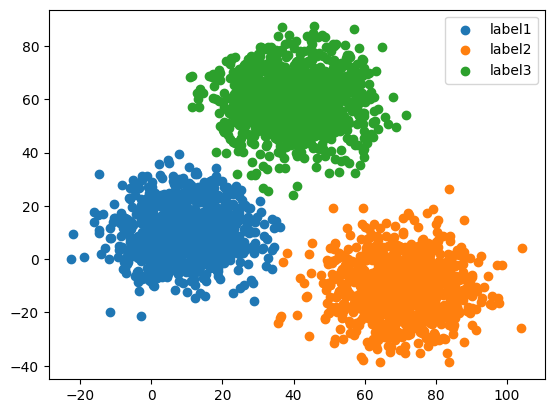

In [3]:
# 画原始数据图
from matplotlib import pyplot as plt
fig1 = plt.figure()
label1 = plt.scatter(data.loc[:,'V1'][y==0],data.loc[:,'V2'][y==0])
label2 = plt.scatter(data.loc[:,'V1'][y==1],data.loc[:,'V2'][y==1])
label3 = plt.scatter(data.loc[:,'V1'][y==2],data.loc[:,'V2'][y==2])
plt.legend((label1,label2,label3),('label1','label2','label3'))
plt.show()

In [4]:
# 训练模型，n_clusters为种类，根据pd.value_counts(y)得出，random_state是随机生成的点，为了让每一次一样，所以固定值
from sklearn.cluster import KMeans
km = KMeans(n_clusters=3,random_state=0)
# 训练不需要y值，无监督学习
km.fit(x)

/Users/mima0000/anaconda3/envs/ai_tec/lib/python3.11/site-packages/sklearn/cluster/_kmeans.py:1412: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)


KMeans(n_clusters=3, random_state=0)

In [5]:
# 评估模型，并获取中心点
from sklearn.metrics import accuracy_score
y_predict = km.predict(x)
acs = accuracy_score(y,y_predict)
centers = km.cluster_centers_
acs,centers

(0.31966666666666665,
 array([[ 40.68362784,  59.71589274],
        [ 69.92418447, -10.11964119],
        [  9.4780459 ,  10.686052  ]]))

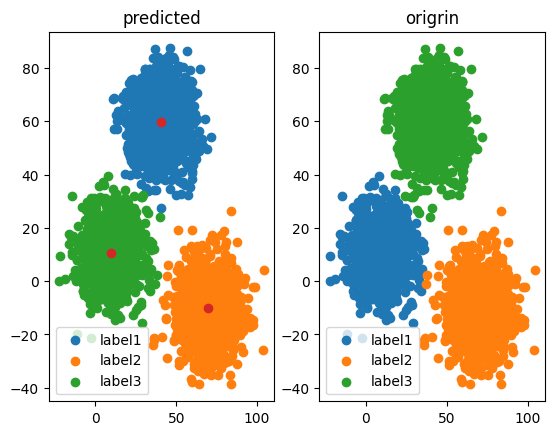

In [6]:
# 模型正确率低，图示预测后的图和中心点，与原图做比较
fig2 = plt.subplot(121)
plt.title('predicted')
label1 = plt.scatter(data.loc[:,'V1'][y_predict==0],data.loc[:,'V2'][y_predict==0])
label2 = plt.scatter(data.loc[:,'V1'][y_predict==1],data.loc[:,'V2'][y_predict==1])
label3 = plt.scatter(data.loc[:,'V1'][y_predict==2],data.loc[:,'V2'][y_predict==2])
plt.legend((label1,label2,label3),('label1','label2','label3'))
plt.scatter(centers[:,0],centers[:,1])

fig3 = plt.subplot(122)
plt.title('origrin')
label1 = plt.scatter(data.loc[:,'V1'][y==0],data.loc[:,'V2'][y==0])
label2 = plt.scatter(data.loc[:,'V1'][y==1],data.loc[:,'V2'][y==1])
label3 = plt.scatter(data.loc[:,'V1'][y==2],data.loc[:,'V2'][y==2])
plt.legend((label1,label2,label3),('label1','label2','label3'))
plt.show()

In [7]:
# 发现分类错误，纠正类别
y_corrected = []
for i in y_predict:
    if i==0:
        y_corrected.append(2)
    elif i==1:
        y_corrected.append(1)
    else:
        y_corrected.append(0)

In [8]:
# 重新评估
acs = accuracy_score(y,y_corrected)
acs

0.997

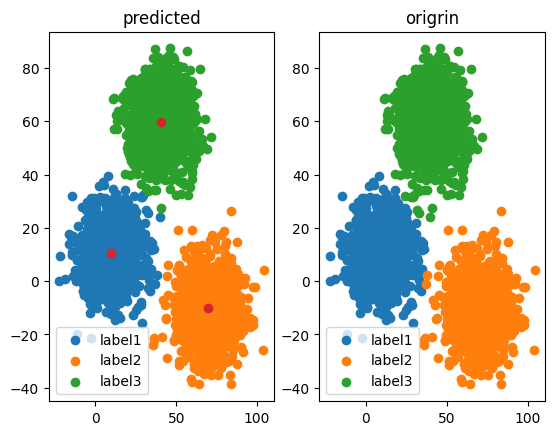

In [9]:
# 正确率特别高，画图

y_corrected = np.array(y_corrected)

fig4 = plt.subplot(121)
plt.title('predicted')
label1 = plt.scatter(data.loc[:,'V1'][y_corrected==0],data.loc[:,'V2'][y_corrected==0])
label2 = plt.scatter(data.loc[:,'V1'][y_corrected==1],data.loc[:,'V2'][y_corrected==1])
label3 = plt.scatter(data.loc[:,'V1'][y_corrected==2],data.loc[:,'V2'][y_corrected==2])
plt.legend((label1,label2,label3),('label1','label2','label3'))
plt.scatter(centers[:,0],centers[:,1])

fig5 = plt.subplot(122)
plt.title('origrin')
label1 = plt.scatter(data.loc[:,'V1'][y==0],data.loc[:,'V2'][y==0])
label2 = plt.scatter(data.loc[:,'V1'][y==1],data.loc[:,'V2'][y==1])
label3 = plt.scatter(data.loc[:,'V1'][y==2],data.loc[:,'V2'][y==2])
plt.legend((label1,label2,label3),('label1','label2','label3'))
plt.show()